# Indian Fraud Monitoring and Drift Detection — CatBoost

This Colab notebook trains a CatBoost fraud model on the synthetic Indian transaction dataset, then monitors performance, drift, calibration, and model retraining over time. All data is synthetic and for coursework only. CatBoost uses the categorical transaction fields directly. The baseline training sample is also restricted to labels available by the simulated training cutoff.


## 1. Download the Kaggle dataset

Run this cell first. If Kaggle asks you to authenticate, add a `KAGGLE_API_TOKEN` secret through the key icon in the left Colab sidebar. Do not paste a token into this notebook.

In [5]:
!pip -q install kagglehub catboost

import kagglehub

DATASET_HANDLE = 'neel1237/indian-fraud-transactions-for-monitoring'
dataset_dir = kagglehub.dataset_download(DATASET_HANDLE)
print('Dataset folder:', dataset_dir)


Dataset folder: /kaggle/input/datasets/neel1237/indian-fraud-transactions-for-monitoring


## 2. Load and validate the data

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

csv_files = list(Path(dataset_dir).rglob('*.csv'))
print('CSV files found:', csv_files)
csv_path = next(path for path in csv_files if path.name == 'financial_fraud_monitoring_synthetic_770k.csv')
df = pd.read_csv(csv_path, low_memory=False)

required_columns = {
    'transaction_id', 'event_timestamp_ist', 'label_available_at_ist',
    'transaction_amount_inr', 'monitoring_window', 'actual_is_fraud'
}
missing_columns = required_columns.difference(df.columns)
assert not missing_columns, f'Missing expected columns: {missing_columns}'
assert len(df) == 770_000, f'Expected 770,000 rows; got {len(df):,}'

df['event_timestamp_ist'] = pd.to_datetime(df['event_timestamp_ist'])
df['label_available_at_ist'] = pd.to_datetime(df['label_available_at_ist'])
df = df.sort_values('event_timestamp_ist').reset_index(drop=True)

print('Shape:', df.shape)
print('Date range:', df['event_timestamp_ist'].min(), 'to', df['event_timestamp_ist'].max())
print('Missing values:', int(df.isna().sum().sum()))
print('Fraud rate: {:.2%}'.format(df['actual_is_fraud'].mean()))
display(df.head())
display(df.groupby('monitoring_window')['actual_is_fraud'].agg(['count', 'mean']).rename(columns={'mean': 'fraud_rate'}))

CSV files found: [PosixPath('/kaggle/input/datasets/neel1237/indian-fraud-transactions-for-monitoring/financial_fraud_monitoring_synthetic_770k.csv')]
Shape: (770000, 33)
Date range: 2025-01-01 00:03:12+05:30 to 2025-12-31 23:58:54+05:30
Missing values: 0
Fraud rate: 7.69%


,transaction_id,event_timestamp_ist,transaction_date,monitoring_window,channel,region,customer_segment,merchant_category,merchant_risk_tier,currency,transaction_amount_inr,transaction_hour,day_of_week,card_present,international,device_trust_score,account_age_days,avg_transaction_amount_30d,amount_to_avg_ratio,days_since_last_txn,transaction_count_24h,failed_auth_24h,distance_from_home_km,is_new_merchant,is_high_risk_country,label_available_at_ist,actual_is_fraud,model_version,model_score,model_prediction,decision,data_drift_regime,concept_drift_regime
0,SYN-0000859,2025-01-01 00:03:12+05:30,2025-01-01,baseline,upi,Andhra Pradesh,small_business,retail,medium,INR,5701.99,0,Wednesday,no,no,69.6,570,3513.07,1.623,6,1,0,22.0,0,0,2025-01-08 21:03:12+05:30,1,fraud_model_v1.0,0.01839,0,approve,stable,none
1,SYN-0000378,2025-01-01 00:09:38+05:30,2025-01-01,baseline,ecommerce,Delhi,student,retail,medium,INR,1278.37,0,Wednesday,no,no,62.8,886,1194.24,1.070,0,1,0,1.3,0,0,2025-01-15 23:09:38+05:30,0,fraud_model_v1.0,0.02627,0,approve,stable,none
2,SYN-0001021,2025-01-01 00:09:54+05:30,2025-01-01,baseline,ecommerce,Rajasthan,salaried,retail,medium,INR,768.29,0,Wednesday,no,no,52.1,631,479.67,1.602,0,2,0,13.6,0,0,2025-01-22 00:09:54+05:30,0,fraud_model_v1.0,0.04061,0,approve,stable,none
3,SYN-0001722,2025-01-01 00:11:33+05:30,2025-01-01,baseline,pos,Delhi,salaried,cash_withdrawal,high,INR,435.44,0,Wednesday,yes,no,45.8,868,551.09,0.790,0,1,0,37.6,1,0,2025-01-29 01:11:33+05:30,0,fraud_model_v1.0,0.05786,0,approve,stable,none
4,SYN-0001290,2025-01-01 00:13:47+05:30,2025-01-01,baseline,ecommerce,Uttar Pradesh,mass_market,grocery,low,INR,2412.19,0,Wednesday,no,no,82.8,1227,3279.95,0.735,1,1,0,4.0,0,0,2025-01-15 18:13:47+05:30,0,fraud_model_v1.0,0.06109,0,approve,stable,none


,count,fraud_rate
monitoring_window,,
baseline,346500,0.052193
drift_period_1,169400,0.096895
drift_period_2,138600,0.116385
transition,115500,0.074156


## 3. Explore the transaction population

These summaries are descriptive only. They show the synthetic patterns built into the coursework dataset.

,count,fraud_rate
channel,,
ecommerce,138400,0.109581
imps_neft_rtgs,23287,0.076824
upi,331154,0.076692
mobile_banking,76972,0.075937
pos,169715,0.055122
atm,30472,0.053918


,count,fraud_rate
region,,
Uttarakhand,7157,0.080760
Delhi,49558,0.079382
Telangana,42407,0.078548
Odisha,17601,0.077836
Uttar Pradesh,77405,0.077760
Gujarat,56669,0.077626
Karnataka,63318,0.077466
Rajasthan,42374,0.076934
Punjab,28532,0.076896


,count,mean,50%,max
actual_is_fraud,,,,
0,710805.0,2480.359356,1419.07,124849.41
1,59195.0,2518.565338,1421.93,132980.54


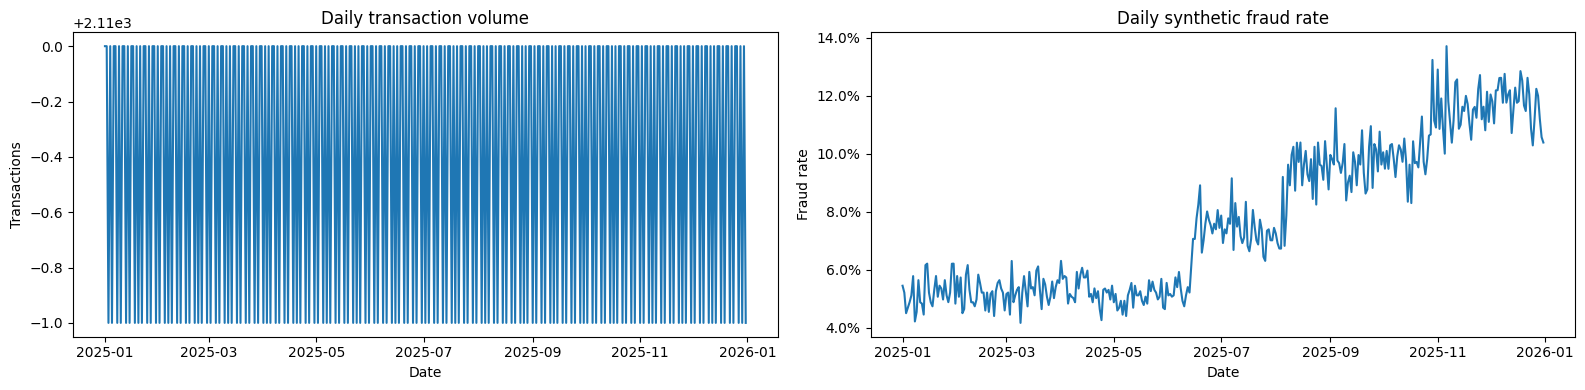

In [7]:
display(df.groupby('channel')['actual_is_fraud'].agg(['count', 'mean']).sort_values('mean', ascending=False).rename(columns={'mean': 'fraud_rate'}))
display(df.groupby('region')['actual_is_fraud'].agg(['count', 'mean']).sort_values('mean', ascending=False).head(10).rename(columns={'mean': 'fraud_rate'}))
display(df.groupby('actual_is_fraud')['transaction_amount_inr'].describe()[['count', 'mean', '50%', 'max']])

daily = (df.groupby(df['event_timestamp_ist'].dt.date)
           .agg(transactions=('transaction_id', 'size'), fraud_rate=('actual_is_fraud', 'mean'))
           .reset_index())
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].plot(pd.to_datetime(daily['event_timestamp_ist']), daily['transactions'])
axes[0].set(title='Daily transaction volume', xlabel='Date', ylabel='Transactions')
axes[1].plot(pd.to_datetime(daily['event_timestamp_ist']), daily['fraud_rate'])
axes[1].set(title='Daily synthetic fraud rate', xlabel='Date', ylabel='Fraud rate')
axes[1].yaxis.set_major_formatter('{x:.1%}')
plt.tight_layout()
plt.show()

## 4. Create leakage-safe features and chronological splits

The target, IDs, timestamps, pre-generated model outputs, and drift labels are excluded from training. CatBoost receives categorical fields as strings and handles them directly. Training rows are limited to outcomes available by the start of baseline validation; later monitoring labels are used only when available.


In [8]:
TARGET = 'actual_is_fraud'
TIME_COL = 'event_timestamp_ist'
LABEL_TIME_COL = 'label_available_at_ist'

# Derived from the event timestamp and available at prediction time.
df['tx_hour_ist'] = df[TIME_COL].dt.hour
df['tx_day_of_week'] = df[TIME_COL].dt.dayofweek
df['is_weekend'] = (df['tx_day_of_week'] >= 5).astype('int8')

EXCLUDED_COLUMNS = {
    TARGET, 'transaction_id', TIME_COL, 'transaction_date', LABEL_TIME_COL,
    'model_version', 'model_score', 'model_prediction', 'decision',
    'monitoring_window', 'data_drift_regime', 'concept_drift_regime',
    # The derived versions below replace these duplicate raw calendar fields.
    'transaction_hour', 'day_of_week',
    # Constant in this dataset; it provides no predictive information.
    'currency'
}
feature_cols = [column for column in df.columns if column not in EXCLUDED_COLUMNS]
numeric_cols = df[feature_cols].select_dtypes(include=np.number).columns.tolist()
categorical_cols = [column for column in feature_cols if column not in numeric_cols]

print('Model features:', feature_cols)
print('Numeric features:', numeric_cols)
print('Categorical features:', categorical_cols)

baseline = df.loc[df['monitoring_window'].eq('baseline')].sort_values(TIME_COL).copy()
split_at = int(len(baseline) * 0.80)
train_df = baseline.iloc[:split_at].copy()
baseline_validation_df = baseline.iloc[split_at:].copy()
# Simulate the information available when the baseline model is trained.
training_cutoff = baseline_validation_df[TIME_COL].min()
train_df = train_df.loc[train_df[LABEL_TIME_COL] <= training_cutoff].copy()
print('Baseline training label cutoff:', training_cutoff)
transition_df = df.loc[df['monitoring_window'].eq('transition')].copy()
drift1_df = df.loc[df['monitoring_window'].eq('drift_period_1')].copy()
drift2_df = df.loc[df['monitoring_window'].eq('drift_period_2')].copy()

for name, frame in {
    'Train baseline': train_df, 'Validation baseline': baseline_validation_df,
    'Transition': transition_df, 'Drift period 1': drift1_df, 'Drift period 2': drift2_df
}.items():
    print(f'{name:20} rows={len(frame):,} | fraud rate={frame[TARGET].mean():.2%} | {frame[TIME_COL].min().date()} to {frame[TIME_COL].max().date()}')

Model features: ['channel', 'region', 'customer_segment', 'merchant_category', 'merchant_risk_tier', 'transaction_amount_inr', 'card_present', 'international', 'device_trust_score', 'account_age_days', 'avg_transaction_amount_30d', 'amount_to_avg_ratio', 'days_since_last_txn', 'transaction_count_24h', 'failed_auth_24h', 'distance_from_home_km', 'is_new_merchant', 'is_high_risk_country', 'tx_hour_ist', 'tx_day_of_week', 'is_weekend']
Numeric features: ['transaction_amount_inr', 'device_trust_score', 'account_age_days', 'avg_transaction_amount_30d', 'amount_to_avg_ratio', 'days_since_last_txn', 'transaction_count_24h', 'failed_auth_24h', 'distance_from_home_km', 'is_new_merchant', 'is_high_risk_country', 'tx_hour_ist', 'tx_day_of_week', 'is_weekend']
Categorical features: ['channel', 'region', 'customer_segment', 'merchant_category', 'merchant_risk_tier', 'card_present', 'international']
Baseline training label cutoff: 2025-05-12 11:54:44+05:30
Train baseline       rows=240,482 | fraud r

## 5. Train the baseline CatBoost fraud model

CatBoost can use categorical columns directly, avoiding ordinal codes that imply an artificial order between categories. This trial uses class weighting to give fraud examples more influence; because weighting can affect probability calibration, the notebook reports Brier score and ECE as well as classification metrics.


In [9]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score
)

# CatBoost accepts categorical columns as strings. Missing categorical values get
# an explicit category; numerical missing values are left for CatBoost to handle.
def prepare_catboost_features(frame):
    X = frame[feature_cols].copy()
    for column in categorical_cols:
        X[column] = X[column].astype('string').fillna('__MISSING__').astype(str)
    return X

CATBOOST_PARAMETERS = {
    'iterations': 800,
    'depth': 8,
    'learning_rate': 0.05,
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',
    'auto_class_weights': 'Balanced',
    'random_seed': RANDOM_STATE,
    'verbose': 200,
    'allow_writing_files': False,
    'thread_count': -1,
}

def make_catboost_model():
    return CatBoostClassifier(**CATBOOST_PARAMETERS)

baseline_model = make_catboost_model()
baseline_model.fit(
    prepare_catboost_features(train_df), train_df[TARGET],
    cat_features=categorical_cols
)
print('Baseline CatBoost model training complete.')


0:	total: 351ms	remaining: 4m 40s
200:	total: 46.3s	remaining: 2m 17s
400:	total: 1m 41s	remaining: 1m 41s
600:	total: 2m 40s	remaining: 53.2s
799:	total: 3m 40s	remaining: 0us
Baseline CatBoost model training complete.


## 6. Select a decision threshold and evaluate each time period

The threshold is selected only on the held-out baseline period using F2, which puts greater weight on recall. It is then held fixed when evaluating later periods.

In [10]:
def model_scores(model, frame):
    return model.predict_proba(prepare_catboost_features(frame))[:, 1]

def expected_calibration_error(y_true, scores, bins=10):
    data = pd.DataFrame({'y': np.asarray(y_true), 'score': np.asarray(scores)})
    data['bin'] = pd.qcut(data['score'], q=bins, duplicates='drop')
    grouped = data.groupby('bin', observed=True).agg(rate=('y', 'mean'), score=('score', 'mean'), n=('y', 'size'))
    return float(np.average(np.abs(grouped['rate'] - grouped['score']), weights=grouped['n']))

def evaluate(y_true, scores, threshold):
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'PR_AUC': average_precision_score(y_true, scores),
        'Brier_score': brier_score_loss(y_true, scores),
        'ECE': expected_calibration_error(y_true, scores),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)
    }

baseline_validation_scores = model_scores(baseline_model, baseline_validation_df)
precision, recall, thresholds = precision_recall_curve(baseline_validation_df[TARGET], baseline_validation_scores)
f2 = 5 * precision[:-1] * recall[:-1] / (4 * precision[:-1] + recall[:-1] + 1e-12)
FRAUD_THRESHOLD = float(thresholds[np.argmax(f2)])
REVIEW_THRESHOLD = float(FRAUD_THRESHOLD * 0.60)
print(f'Fraud threshold: {FRAUD_THRESHOLD:.4f}')
print(f'Manual-review threshold: {REVIEW_THRESHOLD:.4f}')

period_frames = {
    'Baseline validation': baseline_validation_df,
    'Transition': transition_df,
    'Drift period 1': drift1_df,
    'Drift period 2': drift2_df,
}
scored_periods = {}
metric_rows = []
for name, frame in period_frames.items():
    scored = frame.copy()
    scored['replay_model_score'] = model_scores(baseline_model, scored)
    scored['replay_model_prediction'] = (scored['replay_model_score'] >= FRAUD_THRESHOLD).astype(int)
    scored['replay_decision'] = np.select(
        [scored['replay_model_score'] >= FRAUD_THRESHOLD, scored['replay_model_score'] >= REVIEW_THRESHOLD],
        ['DECLINE', 'MANUAL_REVIEW'], default='APPROVE'
    )
    scored_periods[name] = scored
    metrics = evaluate(scored[TARGET], scored['replay_model_score'], FRAUD_THRESHOLD)
    metrics['Period'] = name
    metric_rows.append(metrics)

period_metrics = pd.DataFrame(metric_rows).set_index('Period')
display(period_metrics.style.format({'Accuracy': '{:.2%}', 'Precision': '{:.2%}', 'Recall': '{:.2%}', 'F1': '{:.2%}', 'Specificity': '{:.2%}', 'PR_AUC': '{:.3f}', 'Brier_score': '{:.4f}', 'ECE': '{:.3f}'}))

Fraud threshold: 0.5496
Manual-review threshold: 0.3298


,Accuracy,Precision,Recall,F1,Specificity,PR_AUC,Brier_score,ECE,TP,FP,FN,TN
Period,,,,,,,,,,,,
Baseline validation,87.14%,19.23%,46.52%,27.21%,89.35%,0.184,0.1620,0.319,1666,6999,1915,58720
Transition,85.46%,24.36%,45.65%,31.77%,88.65%,0.233,0.1694,0.306,3910,12140,4655,94795
Drift period 1,84.59%,30.12%,44.74%,36.00%,88.86%,0.283,0.1708,0.286,7343,17037,9071,135949
Drift period 2,83.75%,34.78%,45.30%,39.35%,88.81%,0.321,0.1729,0.270,7308,13703,8823,108766


## 7. Delayed-label performance monitoring

A transaction contributes to supervised metrics only in the week when its outcome has become available. This avoids treating recent, unresolved transactions as legitimate.

/tmp/ipykernel_50/3818635986.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  replay['label_available_week'] = replay[LABEL_TIME_COL].dt.to_period('W').apply(lambda period: period.start_time)


,Accuracy,Precision,Recall,F1,Specificity,PR_AUC,Brier_score,ECE,TP,FP,FN,TN,label_available_week,matured_transactions
0,0.824720,0.513912,0.477204,0.494878,0.900967,0.487233,0.169889,0.215102,314,297,344,2702,2025-05-19,3657
1,0.852495,0.351064,0.470817,0.402216,0.897463,0.320179,0.166254,0.275008,363,671,408,5873,2025-05-26,7315
2,0.859740,0.238162,0.450000,0.311475,0.890818,0.214762,0.166079,0.303848,342,1094,418,8926,2025-06-02,10780
3,0.869274,0.202309,0.466413,0.282209,0.892765,0.193041,0.162350,0.316646,368,1451,421,12080,2025-06-09,14320
4,0.871453,0.202930,0.471033,0.283656,0.894324,0.200027,0.161675,0.316352,374,1469,420,12432,2025-06-16,14695


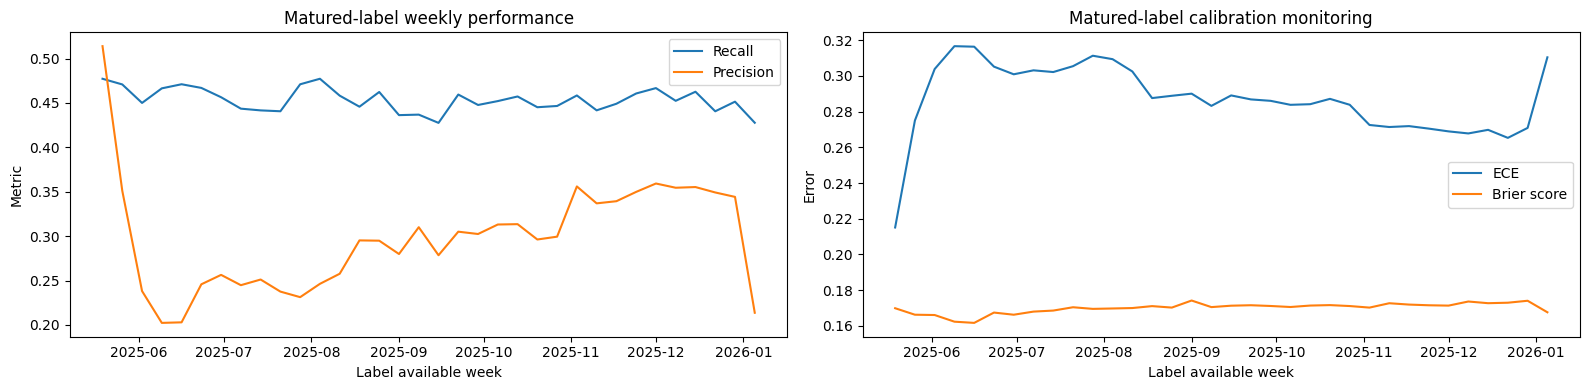

In [11]:
replay = pd.concat(scored_periods.values(), ignore_index=True)
replay['label_available_week'] = replay[LABEL_TIME_COL].dt.to_period('W').apply(lambda period: period.start_time)

weekly_rows = []
for week, frame in replay.groupby('label_available_week', observed=True):
    # Skip a weekly batch only if it has no fraud/non-fraud comparison.
    if frame[TARGET].nunique() < 2:
        continue
    metrics = evaluate(frame[TARGET], frame['replay_model_score'], FRAUD_THRESHOLD)
    metrics['label_available_week'] = week
    metrics['matured_transactions'] = len(frame)
    weekly_rows.append(metrics)

weekly_metrics = pd.DataFrame(weekly_rows).sort_values('label_available_week')
display(weekly_metrics.head())

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].plot(weekly_metrics['label_available_week'], weekly_metrics['Recall'], label='Recall')
axes[0].plot(weekly_metrics['label_available_week'], weekly_metrics['Precision'], label='Precision')
axes[0].set(title='Matured-label weekly performance', xlabel='Label available week', ylabel='Metric')
axes[0].legend()
axes[1].plot(weekly_metrics['label_available_week'], weekly_metrics['ECE'], label='ECE')
axes[1].plot(weekly_metrics['label_available_week'], weekly_metrics['Brier_score'], label='Brier score')
axes[1].set(title='Matured-label calibration monitoring', xlabel='Label available week', ylabel='Error')
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Data and score drift with PSI

PSI compares each later period with the training baseline. Values below 0.10 are commonly treated as small shifts, 0.10–0.25 as moderate shifts, and at least 0.25 as large shifts.

,Period,Feature,PSI
12,Baseline validation,tx_day_of_week,0.008342
21,Baseline validation,replay_model_score,0.000743
11,Baseline validation,tx_hour_ist,0.000675
3,Baseline validation,avg_transaction_amount_30d,0.000299
15,Baseline validation,region,0.000255
4,Baseline validation,amount_to_avg_ratio,0.000237
17,Baseline validation,merchant_category,0.000211
2,Baseline validation,account_age_days,0.000209
50,Drift period 1,transaction_count_24h,0.070387
64,Drift period 1,international,0.013991


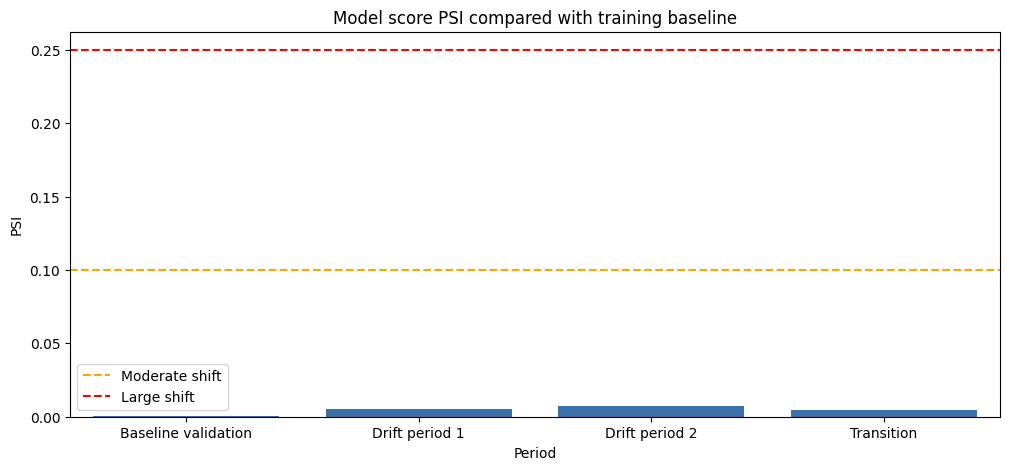

In [12]:
def numeric_psi(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual = pd.Series(actual).dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0] = -np.inf
    edges[-1] = np.inf
    expected_share = np.histogram(expected, bins=edges)[0] / len(expected)
    actual_share = np.histogram(actual, bins=edges)[0] / len(actual)
    expected_share = np.clip(expected_share, 1e-6, None)
    actual_share = np.clip(actual_share, 1e-6, None)
    return float(np.sum((actual_share - expected_share) * np.log(actual_share / expected_share)))

def categorical_psi(expected, actual):
    expected_share = pd.Series(expected).value_counts(normalize=True, dropna=False)
    actual_share = pd.Series(actual).value_counts(normalize=True, dropna=False)
    categories = expected_share.index.union(actual_share.index)
    e = expected_share.reindex(categories, fill_value=0).clip(lower=1e-6)
    a = actual_share.reindex(categories, fill_value=0).clip(lower=1e-6)
    return float(((a - e) * np.log(a / e)).sum())

baseline_scores = model_scores(baseline_model, train_df)
drift_rows = []
for period_name, period_df in period_frames.items():
    for column in numeric_cols:
        drift_rows.append({'Period': period_name, 'Feature': column, 'PSI': numeric_psi(train_df[column], period_df[column])})
    for column in categorical_cols:
        drift_rows.append({'Period': period_name, 'Feature': column, 'PSI': categorical_psi(train_df[column], period_df[column])})
    drift_rows.append({'Period': period_name, 'Feature': 'replay_model_score', 'PSI': numeric_psi(baseline_scores, scored_periods[period_name]['replay_model_score'])})

drift_results = pd.DataFrame(drift_rows).sort_values(['Period', 'PSI'], ascending=[True, False])
display(drift_results.groupby('Period', group_keys=False).head(8))

plt.figure(figsize=(12, 5))
plot_data = drift_results[drift_results['Feature'].eq('replay_model_score')]
sns.barplot(data=plot_data, x='Period', y='PSI', color='#2a6fbb')
plt.axhline(0.10, color='orange', linestyle='--', label='Moderate shift')
plt.axhline(0.25, color='red', linestyle='--', label='Large shift')
plt.title('Model score PSI compared with training baseline')
plt.legend()
plt.show()

## 9. Alerts and slice investigation

In [13]:
baseline_metrics = period_metrics.loc['Baseline validation']
alert_rows = []
for period_name in ['Transition', 'Drift period 1', 'Drift period 2']:
    current = period_metrics.loc[period_name]
    score_psi = drift_results.loc[(drift_results['Period'] == period_name) & (drift_results['Feature'] == 'replay_model_score'), 'PSI'].iloc[0]
    max_feature_psi = drift_results.loc[(drift_results['Period'] == period_name) & (drift_results['Feature'] != 'replay_model_score'), 'PSI'].max()
    alert_rows.append({
        'Period': period_name,
        'Recall_drop_alert': current['Recall'] < baseline_metrics['Recall'] - 0.10,
        'Calibration_alert': current['ECE'] > baseline_metrics['ECE'] + 0.03,
        'Drift_alert': score_psi >= 0.25 or max_feature_psi >= 0.25,
        'Score_PSI': score_psi, 'Maximum_feature_PSI': max_feature_psi
    })
alerts = pd.DataFrame(alert_rows)
display(alerts.style.format({'Score_PSI': '{:.3f}', 'Maximum_feature_PSI': '{:.3f}'}))

# Example investigation: fraud rate and model recall by high-level operational slice.
def slice_metrics(frame, group_col):
    rows = []
    for group, subset in frame.groupby(group_col, observed=True):
        if len(subset) < 100 or subset[TARGET].nunique() < 2:
            continue
        result = evaluate(subset[TARGET], subset['replay_model_score'], FRAUD_THRESHOLD)
        result[group_col] = group
        result['transactions'] = len(subset)
        rows.append(result)
    return pd.DataFrame(rows).sort_values('Recall')

for group_col in ['channel', 'region', 'customer_segment']:
    print(f'\nDrift period 1 by {group_col}:')
    display(slice_metrics(scored_periods['Drift period 1'], group_col)[[group_col, 'transactions', 'Precision', 'Recall', 'PR_AUC', 'FN']].head(10))

,Period,Recall_drop_alert,Calibration_alert,Drift_alert,Score_PSI,Maximum_feature_PSI
0,Transition,False,False,False,0.004,0.071
1,Drift period 1,False,False,False,0.005,0.070
2,Drift period 2,False,False,False,0.007,0.069



Drift period 1 by channel:


,channel,transactions,Precision,Recall,PR_AUC,FN
0,atm,6689,0.272293,0.375000,0.207403,285
4,pos,37484,0.266735,0.400612,0.216329,1568
2,imps_neft_rtgs,5089,0.307692,0.412451,0.270413,302
5,upi,72843,0.312774,0.434130,0.266645,3999
3,mobile_banking,17065,0.292232,0.444375,0.262591,889
1,ecommerce,30230,0.309489,0.512617,0.350312,2028



Drift period 1 by region:


,region,transactions,Precision,Recall,PR_AUC,FN
1,Assam,2309,0.282230,0.385714,0.237204,129
3,Chhattisgarh,2310,0.302326,0.390558,0.288753,142
12,Odisha,3889,0.250454,0.395415,0.244860,211
15,Tamil Nadu,13976,0.289862,0.422420,0.258914,778
14,Rajasthan,9264,0.295732,0.433036,0.272455,508
6,Haryana,6105,0.320423,0.436800,0.288821,352
4,Delhi,10926,0.298686,0.440141,0.298985,636
11,Maharashtra,20353,0.310272,0.440602,0.282972,1116
5,Gujarat,12532,0.284004,0.441624,0.270223,660
13,Punjab,6258,0.306378,0.447587,0.288228,332



Drift period 1 by customer_segment:


,customer_segment,transactions,Precision,Recall,PR_AUC,FN
0,affluent,22144,0.300826,0.423650,0.275199,1238
2,salaried,45596,0.297691,0.446122,0.278641,2385
1,mass_market,68113,0.303090,0.449916,0.281853,3586
4,student,11726,0.292850,0.457536,0.307319,709
3,small_business,21821,0.308200,0.459700,0.290268,1153


## 10. Candidate retraining comparison

The candidate can only learn from outcomes available by the end of Drift period 1. Drift period 2 remains the untouched out-of-time holdout.

In [14]:
retrain_cutoff = drift1_df[TIME_COL].max()
retraining_pool = pd.concat([train_df, baseline_validation_df, transition_df, drift1_df], ignore_index=True)
matured_training_data = retraining_pool.loc[retraining_pool[LABEL_TIME_COL] <= retrain_cutoff].copy()
print(f'Retraining pool: {len(matured_training_data):,} rows with labels available by {retrain_cutoff.date()}')

candidate_model = make_catboost_model()
candidate_model.fit(
    prepare_catboost_features(matured_training_data), matured_training_data[TARGET],
    cat_features=categorical_cols
)

holdout = drift2_df.copy()
baseline_holdout_scores = model_scores(baseline_model, holdout)
candidate_holdout_scores = model_scores(candidate_model, holdout)
comparison = pd.DataFrame([
    {'Model': 'Baseline v1.0', **evaluate(holdout[TARGET], baseline_holdout_scores, FRAUD_THRESHOLD)},
    {'Model': 'Candidate v2.0', **evaluate(holdout[TARGET], candidate_holdout_scores, FRAUD_THRESHOLD)},
]).set_index('Model')
display(comparison.style.format({'Accuracy': '{:.2%}', 'Precision': '{:.2%}', 'Recall': '{:.2%}', 'F1': '{:.2%}', 'Specificity': '{:.2%}', 'PR_AUC': '{:.3f}', 'Brier_score': '{:.4f}', 'ECE': '{:.3f}'}))

print('Interpretation: consider promoting the candidate only if it improves the selected business metrics on this untouched holdout, without creating an unacceptable increase in false positives.')

Retraining pool: 560,081 rows with labels available by 2025-10-27
0:	total: 787ms	remaining: 10m 29s
200:	total: 1m 49s	remaining: 5m 27s
400:	total: 3m 52s	remaining: 3m 51s
600:	total: 6m 4s	remaining: 2m
799:	total: 8m 16s	remaining: 0us


,Accuracy,Precision,Recall,F1,Specificity,PR_AUC,Brier_score,ECE,TP,FP,FN,TN
Model,,,,,,,,,,,,
Baseline v1.0,83.75%,34.78%,45.30%,39.35%,88.81%,0.321,0.1729,0.270,7308,13703,8823,108766
Candidate v2.0,82.58%,33.19%,49.01%,39.58%,87.01%,0.336,0.1876,0.301,7905,15912,8226,106557


Interpretation: consider promoting the candidate only if it improves the selected business metrics on this untouched holdout, without creating an unacceptable increase in false positives.


## 11. Save results

Download these tables for your report or presentation.

In [15]:
from pathlib import Path
from google.colab import files

output_dir = Path('/content/fraud_monitoring_outputs')
output_dir.mkdir(exist_ok=True)
period_metrics.to_csv(output_dir / 'period_metrics.csv')
weekly_metrics.to_csv(output_dir / 'weekly_matured_label_metrics.csv', index=False)
drift_results.to_csv(output_dir / 'psi_drift_results.csv', index=False)
alerts.to_csv(output_dir / 'monitoring_alerts.csv', index=False)
comparison.to_csv(output_dir / 'candidate_comparison_drift_period_2.csv')

!zip -qr /content/fraud_monitoring_outputs.zip /content/fraud_monitoring_outputs
files.download('/content/fraud_monitoring_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>